# **TP1 - Variable Types & Descriptive Statistics**

<b>Exploratory Data Analysis & Unsupervised Learning</b><br>
**Course: Dr. HAS Sothea** <br> 
**TP: Ms. UANN Sreyvi** <br>

-------

**Objective**: This initial practical session is designed to enhance your understanding of various data variable types and the corresponding statistical and graphical tools suitable for each type.

---------

> **The `Jupyter Notebook` for this TP can be downloaded here: [TP1-Gapminder](https://hassothea.github.io/I5_EDA_ITC/TPs/TP1_Variable_Types_Descriptive_Statistics.ipynb)**.

-------

# 1. `Gapminder` dataset

[`Gapminder`](https://pypi.org/project/gapminder/) is an excerpt of data available at [https://gapminder.org](https://www.gapminder.org/). For each of $142$ countries (`country`), the package provides values for life expectancy (`lifeExp`), GDP per capita (`gdpPercap`), and population (`pop`), every five years, from $1952$ to $2007$ (`year`). It is initially used in [Jennifer Bryan's excellent `gapminder` teaching package for R](https://github.com/jennybc/gapminder/) ([`ggplot`](https://ggplot2.tidyverse.org/), [`tidyverse`](https://www.tidyverse.org/), and more). For more information about `gapminder`: 
- Documentation: [https://www.gapminder.org/data/documentation/](https://www.gapminder.org/data/documentation/)
- A short demonstration video is available here: [Hans Rosling's 200 Countries, 200 Years, 4 Minutes - The Joy of Stats - BBC Four](https://youtu.be/jbkSRLYSojo?si=qipg08VIi999hEgo).

In [1]:
# useful packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from scipy import stats

#%pip install gapminder  (for installing gapminder if you haven't had one)
from gapminder import gapminder
print(f"* Number of observations: {gapminder.shape[0]}")
gapminder.sample(5)

* Number of observations: 1704


,country,continent,year,lifeExp,pop,gdpPercap
175,Brazil,Americas,1987,65.205,142938076,7807.095818
464,Egypt,Africa,1992,63.674,59402198,3794.755195
1395,Somalia,Africa,1967,38.977,3428839,1284.733180
1332,Serbia,Europe,1952,57.996,6860147,3581.459448
1145,Norway,Europe,1977,75.370,4043205,23311.349390


----------

# 2. Variable types

`EDA` involves summarizing and visualizing data to uncover patterns, detect anomalies, and understand relationships between variables. Statistical summaries, such as mean, median, and standard deviation, are essential tools in this process.

- Which variables are considered quantitative and which are qualitative? 

> Hint: You can check the default column types by using `gapminder.dtypes`. But this may not be accurate because some categorical data may be encoded using numerical values.

In [2]:
# Check column data types and dataset summary
print("--- Data Types (gapminder.dtypes) ---")
print(gapminder.dtypes)

print("\n--- Dataset Info ---")
gapminder.info()

print("\n--- Unique count per column ---")
print(gapminder.nunique())

--- Data Types (gapminder.dtypes) ---
country          str
continent        str
year           int64
lifeExp      float64
pop            int64
gdpPercap    float64
dtype: object

--- Dataset Info ---
<class 'pandas.DataFrame'>
RangeIndex: 1704 entries, 0 to 1703
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   country    1704 non-null   str    
 1   continent  1704 non-null   str    
 2   year       1704 non-null   int64  
 3   lifeExp    1704 non-null   float64
 4   pop        1704 non-null   int64  
 5   gdpPercap  1704 non-null   float64
dtypes: float64(2), int64(2), str(2)
memory usage: 103.7 KB

--- Unique count per column ---
country       142
continent       5
year           12
lifeExp      1626
pop          1704
gdpPercap    1704
dtype: int64


In [3]:
# Distinguishing quantitative and qualitative columns using select_dtypes
num_cols = gapminder.select_dtypes(include='number').columns.tolist()
cat_cols = gapminder.select_dtypes(exclude='number').columns.tolist()

print(f"Quantitative (numerical) columns: {num_cols}")
print(f"Qualitative (categorical) columns: {cat_cols}")

Quantitative (numerical) columns: ['year', 'lifeExp', 'pop', 'gdpPercap']
Qualitative (categorical) columns: ['country', 'continent']


> ### **Summary of Variable Types & Measurement Scales**
> 
> In Statistics and Exploratory Data Analysis, variables are classified into two broad families:
> 
> 1. **Quantitative (Numerical) Variables**: Measure quantities on a numeric scale where arithmetic operations (mean, sum, subtraction) are meaningful.
>    - **Continuous**: Can assume any real value within an interval.
>      - `lifeExp` (Life Expectancy in years): Continuous ratio variable (absolute zero exists).
>      - `gdpPercap` (GDP per capita in inflation-adjusted US dollars): Continuous ratio variable.
>    - **Discrete**: Take distinct, countable values (typically integers).
>      - `pop` (Total population count): Count variable (discrete ratio scale).
>      - `year` (Observation year: 1952, 1957, ..., 2007): Discrete interval variable, often treated as a discrete time index or ordinal factor.
> 
> 2. **Qualitative (Categorical) Variables**: Represent categories, characteristics, or labels. Arithmetic operations are meaningless; we analyze frequencies, proportions, and modes.
>    - **Nominal**: Unordered categories.
>      - `country`: Country name (142 distinct entities).
>      - `continent`: Geographical region (5 distinct categories: Africa, Americas, Asia, Europe, Oceania).
> 
> | Variable | Pandas dtype | Variable Nature | Measurement Scale | Description |
> | :--- | :--- | :--- | :--- | :--- |
> | `country` | `object` / string | Qualitative | Nominal | Name of the nation |
> | `continent` | `object` / string | Qualitative | Nominal | Continental classification |
> | `year` | `int64` | Quantitative | Interval / Discrete | Year of record (every 5 years: 1952–2007) |
> | `lifeExp` | `float64` | Quantitative | Ratio (Continuous) | Life expectancy at birth (years) |
> | `pop` | `int64` | Quantitative | Ratio (Discrete count) | Total population size |
> | `gdpPercap` | `float64` | Quantitative | Ratio (Continuous) | GDP per capita in US Dollars (inflation-adjusted) |

## 2.1 Quantitative variables

1. In year 2002, 
- Compute suitable statistics for each quantitative variable (excluding `year`) to obtain an overall summary.
- Recall the definitions of **skewness** and **kurtosis** introduced in the course. 
- Compute these metrics for each quantitative variable and explain the distribution of each variable based on these values.

In [4]:
# Filter data for the year 2002
data2002 = gapminder.query("year == 2002").copy()
print(f"Data 2002 Shape: {data2002.shape} (142 countries, 6 columns)")
data2002.head()

Data 2002 Shape: (142, 6) (142 countries, 6 columns)


,country,continent,year,lifeExp,pop,gdpPercap
10,Afghanistan,Asia,2002,42.129,25268405,726.734055
22,Albania,Europe,2002,75.651,3508512,4604.211737
34,Algeria,Africa,2002,70.994,31287142,5288.040382
46,Angola,Africa,2002,41.003,10866106,2773.287312
58,Argentina,Americas,2002,74.340,38331121,8797.640716


In [5]:
# Check Cambodia data in 2002
data2002.query("country == 'Cambodia'")

,country,continent,year,lifeExp,pop,gdpPercap
226,Cambodia,Asia,2002,56.752,12926707,896.226015


### 1. Descriptive Statistics for 2002
We compute central tendency (mean, median), dispersion (standard deviation, IQR, min, max), and distribution shape metrics (skewness, kurtosis).

In [6]:
# 1. Summary statistics for quantitative variables in 2002
quant_vars = ['lifeExp', 'pop', 'gdpPercap']

# Basic describe table
desc = data2002[quant_vars].describe().T
desc['IQR'] = desc['75%'] - desc['25%']
desc['skewness'] = data2002[quant_vars].skew()
desc['kurtosis (excess)'] = data2002[quant_vars].kurt()
desc['variance'] = data2002[quant_vars].var()

print("=== Complete Descriptive Statistics (Year 2002) ===")
desc[['mean', 'std', 'min', '25%', '50%', '75%', 'max', 'IQR', 'skewness', 'kurtosis (excess)']]

=== Complete Descriptive Statistics (Year 2002) ===


,mean,std,min,25%,50%,75%,max,IQR,skewness,kurtosis (excess)
lifeExp,6.569492e+01,1.227982e+01,39.193000,5.552225e+01,7.082550e+01,7.545925e+01,8.200000e+01,1.993700e+01,-0.632298,-0.954877
pop,4.145759e+07,1.408483e+08,170372.000000,4.173506e+06,1.037292e+07,2.654556e+07,1.280400e+09,2.237205e+07,7.471563,59.604234
gdpPercap,9.917848e+03,1.115411e+04,241.165876,1.409567e+03,5.319805e+03,1.335951e+04,4.468398e+04,1.194994e+04,1.258700,0.342356


### Definitions of Skewness and Kurtosis

- **Skewness ($g_1$)**: Measures the **asymmetry** of the probability distribution about its mean.
  $$\text{Skewness} = \frac{\frac{1}{n} \sum_{i=1}^n (x_i - \bar{x})^3}{s^3}$$
  - $g_1 \approx 0$: Symmetric distribution (like a normal distribution).
  - $g_1 > 0$: **Positive / Right-skewed** (long right tail; mean > median).
  - $g_1 < 0$: **Negative / Left-skewed** (long left tail; mean < median).

- **Kurtosis ($g_2$) (Fisher Excess Kurtosis)**: Measures the **peakedness** and **tail weight** relative to a normal distribution.
  $$\text{Kurtosis} = \frac{\frac{1}{n} \sum_{i=1}^n (x_i - \bar{x})^4}{s^4} - 3$$
  - $g_2 \approx 0$: **Mesokurtic** (normal-like tails and peakedness).
  - $g_2 > 0$: **Leptokurtic** (sharp central peak and heavy tails with extreme outliers).
  - $g_2 < 0$: **Platykurtic** (flat central peak and light tails, fewer extreme outliers).

#### **Interpretation for Year 2002 Variables**:
1. **`lifeExp` (Life Expectancy)**:
   - Skewness = **$-0.63$** (Moderately left-skewed): The majority of countries enjoy high life expectancy (median 70.8 years > mean 65.7 years), with a trailing left tail composed of severely disadvantaged countries (primarily affected by wars or epidemics).
   - Kurtosis = **$-0.95$** (Platykurtic): Flatter than a normal distribution with fewer extreme outlier values and a broader spread across mid-to-high values.
2. **`pop` (Population)**:
   - Skewness = **$+7.47$** (Extremely right-skewed): A vast majority of countries have small-to-moderate populations (median 10.4M), while a few mega-countries (China >1.28B, India >1.05B) stretch the right tail enormously.
   - Kurtosis = **$+59.60$** (Extremely leptokurtic): Extremely heavy tails and huge outlier spikes caused by China and India.
3. **`gdpPercap` (GDP per Capita)**:
   - Skewness = **$+1.26$** (Strongly right-skewed): Most nations cluster at low-to-middle income levels (median \$5,319.80 < mean \$9,917.85), while a handful of wealthy nations stretch into the upper \$30,000–\$45,000 range.
   - Kurtosis = **$+0.34$** (Slightly leptokurtic): Modest outlier weight in the upper tail.

3. According to the data, in 2002:
- Which country is the richest? 
- Which country is the poorest?
- Which country is the healthiest?
- Which country is the unhealthiest?

In [7]:
# Extremes in 2002
richest_2002 = data2002.loc[data2002['gdpPercap'].idxmax()]
poorest_2002 = data2002.loc[data2002['gdpPercap'].idxmin()]
healthiest_2002 = data2002.loc[data2002['lifeExp'].idxmax()]
unhealthiest_2002 = data2002.loc[data2002['lifeExp'].idxmin()]

print("=" * 65)
print(f"🏆 Richest Country:      {richest_2002['country']} ({richest_2002['continent']}) - GDP/capita: ${richest_2002['gdpPercap']:,.2f}")
print(f"📉 Poorest Country:      {poorest_2002['country']} ({poorest_2002['continent']}) - GDP/capita: ${poorest_2002['gdpPercap']:,.2f}")
print(f"💚 Healthiest Country:   {healthiest_2002['country']} ({healthiest_2002['continent']}) - Life Expectancy: {healthiest_2002['lifeExp']:.2f} years")
print(f"💔 Unhealthiest Country: {unhealthiest_2002['country']} ({unhealthiest_2002['continent']}) - Life Expectancy: {unhealthiest_2002['lifeExp']:.2f} years")
print("=" * 65)

🏆 Richest Country:      Norway (Europe) - GDP/capita: $44,683.98
📉 Poorest Country:      Congo, Dem. Rep. (Africa) - GDP/capita: $241.17
💚 Healthiest Country:   Japan (Asia) - Life Expectancy: 82.00 years
💔 Unhealthiest Country: Zambia (Africa) - Life Expectancy: 39.19 years


2. Graphically represent the distribution of each variable for the year $2002$. After plotting the distributions, provide a brief explanation for each variable.

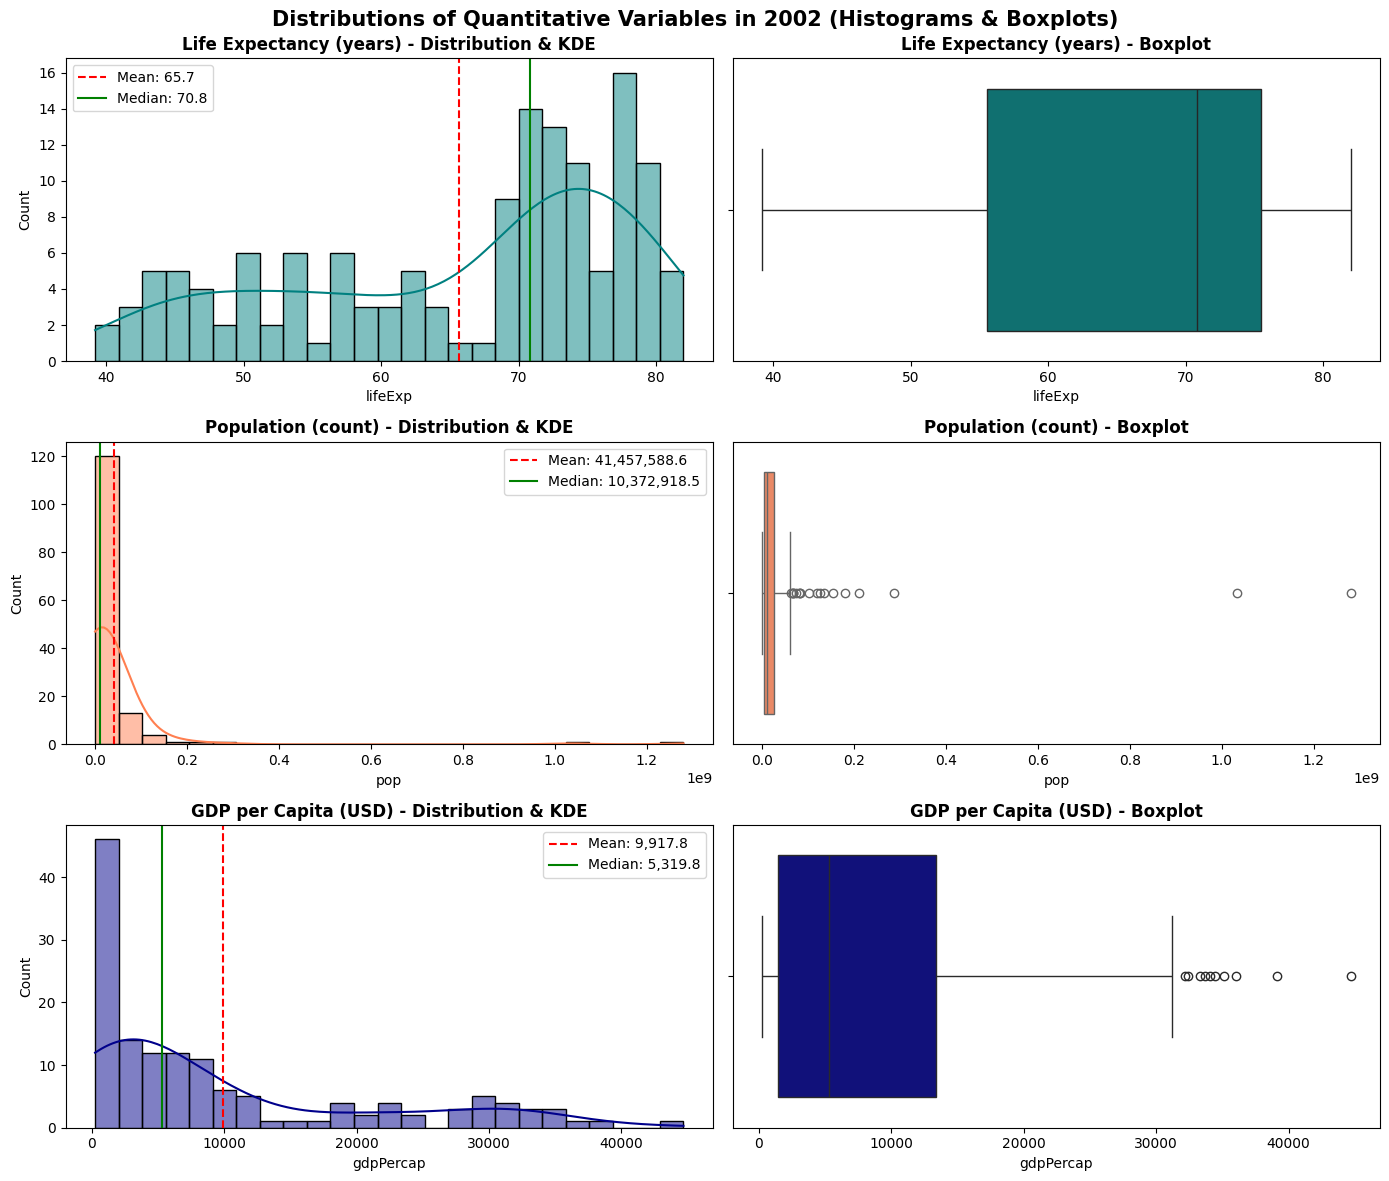

In [8]:
# Visualizing distributions of all 3 quantitative variables in 2002
fig, axes = plt.subplots(3, 2, figsize=(14, 12))
fig.suptitle('Distributions of Quantitative Variables in 2002 (Histograms & Boxplots)', fontsize=15, fontweight='bold')

variables = [
    ('lifeExp', 'Life Expectancy (years)', 'teal'),
    ('pop', 'Population (count)', 'coral'),
    ('gdpPercap', 'GDP per Capita (USD)', 'darkblue')
]

for idx, (col, label, color) in enumerate(variables):
    # Histogram + KDE
    sns.histplot(data=data2002, x=col, kde=True, ax=axes[idx, 0], color=color, bins=25)
    mean_val = data2002[col].mean()
    median_val = data2002[col].median()
    axes[idx, 0].axvline(mean_val, color='red', linestyle='--', linewidth=1.5, label=f"Mean: {mean_val:,.1f}")
    axes[idx, 0].axvline(median_val, color='green', linestyle='-', linewidth=1.5, label=f"Median: {median_val:,.1f}")
    axes[idx, 0].set_title(f'{label} - Distribution & KDE', fontweight='bold')
    axes[idx, 0].legend()
    
    # Boxplot
    sns.boxplot(data=data2002, x=col, ax=axes[idx, 1], color=color)
    axes[idx, 1].set_title(f'{label} - Boxplot', fontweight='bold')

plt.tight_layout()
plt.show()

> ### **Distribution Interpretations (Year 2002)**:
> 
> 1. **Life Expectancy (`lifeExp`)**:
>    - The distribution is **bimodal / left-skewed**. A major peak sits around 70–78 years (developed and middle-income nations), with a smaller bump below 50 years representing Sub-Saharan African countries heavily impacted by the HIV/AIDS epidemic and severe socioeconomic distress.
>    - Notice that $\text{Median} (70.8) > \text{Mean} (65.7)$, confirming negative skewness.
> 
> 2. **Population (`pop`)**:
>    - **Extreme positive skewness**. Almost all 142 data points are compressed near zero on the boxplot, with two extreme isolated points on the far right: China ($\approx 1.28$ billion) and India ($\approx 1.05$ billion).
>    - To make population visually interpretable, a **logarithmic transformation** ($\log_{10}(\text{pop})$) is typically recommended.
> 
> 3. **GDP per Capita (`gdpPercap`)**:
>    - **Right-skewed with high inequality**. The vast majority of countries have a GDP per capita below \$10,000, while a long right tail extends towards \$45,000 (Norway, USA, Switzerland).
>    - The median (\$5,319) is substantially smaller than the mean (\$9,918), showing that high-income nations pull the arithmetic average upwards.

4. Repeat the previous question for the year 1977. Before computing, can you guess which country had the lowest life expectancy around that year?

In [9]:
# Filter data for 1977
data1977 = gapminder.query("year == 1977").copy()

# Extremes in 1977
lowest_1977 = data1977.loc[data1977['lifeExp'].idxmin()]
highest_1977 = data1977.loc[data1977['lifeExp'].idxmax()]
richest_1977 = data1977.loc[data1977['gdpPercap'].idxmax()]
poorest_1977 = data1977.loc[data1977['gdpPercap'].idxmin()]

print("=" * 65)
print("=== Extremes in Year 1977 ===")
print(f"💔 Lowest Life Expectancy:  {lowest_1977['country']} ({lowest_1977['continent']}) - {lowest_1977['lifeExp']:.2f} years")
print(f"💚 Highest Life Expectancy: {highest_1977['country']} ({highest_1977['continent']}) - {highest_1977['lifeExp']:.2f} years")
print(f"🏆 Richest Country:         {richest_1977['country']} ({richest_1977['continent']}) - GDP/capita: ${richest_1977['gdpPercap']:,.2f}")
print(f"📉 Poorest Country:         {poorest_1977['country']} ({poorest_1977['continent']}) - GDP/capita: ${poorest_1977['gdpPercap']:,.2f}")
print("=" * 65)

=== Extremes in Year 1977 ===
💔 Lowest Life Expectancy:  Cambodia (Asia) - 31.22 years
💚 Highest Life Expectancy: Iceland (Europe) - 76.11 years
🏆 Richest Country:         Kuwait (Asia) - GDP/capita: $59,265.48
📉 Poorest Country:         Myanmar (Asia) - GDP/capita: $371.00


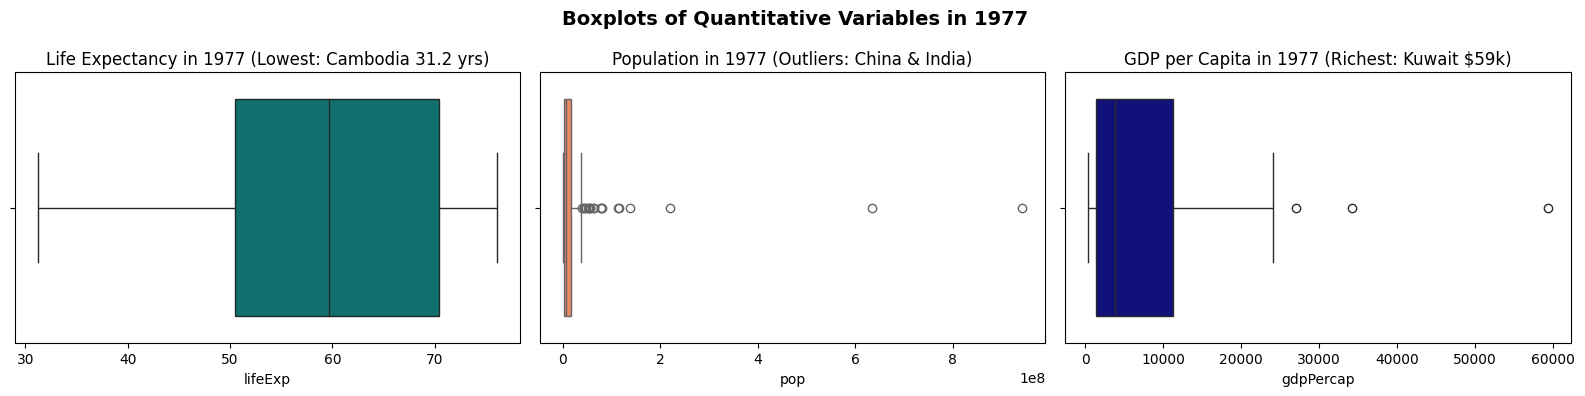

In [10]:
# Visualizing 1977 Distributions
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
fig.suptitle('Boxplots of Quantitative Variables in 1977', fontsize=14, fontweight='bold')

sns.boxplot(data=data1977, x='lifeExp', ax=axes[0], color='teal')
axes[0].set_title('Life Expectancy in 1977 (Lowest: Cambodia 31.2 yrs)')

sns.boxplot(data=data1977, x='pop', ax=axes[1], color='coral')
axes[1].set_title('Population in 1977 (Outliers: China & India)')

sns.boxplot(data=data1977, x='gdpPercap', ax=axes[2], color='darkblue')
axes[2].set_title('GDP per Capita in 1977 (Richest: Kuwait $59k)')

plt.tight_layout()
plt.show()

> ### **Historical Note on 1977**:
> - **Lowest Life Expectancy**: **Cambodia (31.22 years)**. 
>   Around 1975–1979, Cambodia suffered under the brutal **Khmer Rouge regime (Democratic Kampuchea)**, which resulted in mass atrocities, forced labor, famine, and medical collapse, tragically killing an estimated 1.5 to 2 million people and dropping life expectancy to unprecedented historical lows.
> - **Highest Life Expectancy**: **Iceland (76.11 years)**.
> - **Richest Country in 1977**: **Kuwait (\$59,265.48)**, boosted by the 1970s global oil boom.
> - **Poorest Country in 1977**: **Myanmar (\$371.00)**.

## 2.2. Qualitative variables

Qualitative variables are simpler than the quantitative ones, as we primarily focus on the proportion or frequency of each category. In our dataset, the existing qualitative variables are not suitable for analysis because they are repeated each year. Therefore, we will create three new qualitative variables associated with the three quantitative columns by copping them into three categories each.

In year 2002,

1. Add the following three variables to the `gapminder` dataset by grouping each quantitative variable into $3$ groups.
- Create variable `gdpQual` with three categories: [**"developing"**, **"moderate"**, **"developed"**] using variable `gdpPercap`.
- Create variable `popQual` with three categories: [**"small"**, **"medium"**, **"large"**] using variable `pop`.
- Create variable `lifeExpQual` with three categories: [**"unhealthy"**, **"moderate"**, **"healthy"**] using variable `lifeExp`.

> Hint: you may find `pd.cut` function helpful.

In [11]:
# 1. Categorization for Year 2002 using pd.cut (equal-width binning)
data2002['gdpQual'] = pd.cut(
    data2002['gdpPercap'],
    bins=3,
    labels=['developing', 'moderate', 'developed']
)

data2002['popQual'] = pd.cut(
    data2002['pop'],
    bins=3,
    labels=['small', 'medium', 'large']
)

data2002['lifeExpQual'] = pd.cut(
    data2002['lifeExp'],
    bins=3,
    labels=['unhealthy', 'moderate', 'healthy']
)

data2002[['country', 'continent', 'gdpPercap', 'gdpQual', 'pop', 'popQual', 'lifeExp', 'lifeExpQual']].sample(8, random_state=42)

,country,continent,gdpPercap,gdpQual,pop,popQual,lifeExp,lifeExpQual
1582,Turkey,Europe,6508.085718,developing,67308928,small,70.845,healthy
238,Cameroon,Africa,1934.011449,developing,15929988,small,49.856,unhealthy
982,Mauritius,Africa,9021.815894,developing,1200206,small,71.954,healthy
1162,Oman,Asia,19774.836870,moderate,2713462,small,74.193,healthy
682,Hungary,Europe,14843.935560,developing,10083313,small,72.590,healthy
154,Bosnia and Herzegovina,Europe,6018.975239,developing,4165416,small,74.090,healthy
1186,Panama,Americas,7356.031934,developing,2990875,small,74.712,healthy
790,Jamaica,Americas,6994.774861,developing,2664659,small,72.047,healthy


2. Compute the appropriate statistical values and graphically represent the distribution of each newly created qualitative variable.

In [12]:
# Frequency tables, relative frequencies, and modes
qual_vars = ['gdpQual', 'popQual', 'lifeExpQual']

for q_var in qual_vars:
    counts = data2002[q_var].value_counts().sort_index()
    percentages = data2002[q_var].value_counts(normalize=True).sort_index() * 100
    cum_pct = percentages.cumsum()
    mode_val = data2002[q_var].mode()[0]
    
    summary_df = pd.DataFrame({
        'Frequency (Count)': counts,
        'Relative Frequency (%)': percentages.round(2),
        'Cumulative (%)': cum_pct.round(2)
    })
    print(f"=== Statistical Distribution of `{q_var}` (Mode: '{mode_val}') ===")
    display(summary_df)
    print()

=== Statistical Distribution of `gdpQual` (Mode: 'developing') ===


,Frequency (Count),Relative Frequency (%),Cumulative (%)
gdpQual,,,
developing,108,76.06,76.06
moderate,19,13.38,89.44
developed,15,10.56,100.00



=== Statistical Distribution of `popQual` (Mode: 'small') ===


,Frequency (Count),Relative Frequency (%),Cumulative (%)
popQual,,,
small,140,98.59,98.59
medium,0,0.00,98.59
large,2,1.41,100.00



=== Statistical Distribution of `lifeExpQual` (Mode: 'healthy') ===


,Frequency (Count),Relative Frequency (%),Cumulative (%)
lifeExpQual,,,
unhealthy,32,22.54,22.54
moderate,26,18.31,40.85
healthy,84,59.15,100.00


- Graphically represent them and describe the graph.

C:\Users\Sreynich\AppData\Local\Temp\ipykernel_17204\445166101.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.index, y=counts.values, ax=axes[i], palette='Blues_d' if i==0 else ('Purples_d' if i==1 else 'Greens_d'))
C:\Users\Sreynich\AppData\Local\Temp\ipykernel_17204\445166101.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.index, y=counts.values, ax=axes[i], palette='Blues_d' if i==0 else ('Purples_d' if i==1 else 'Greens_d'))
C:\Users\Sreynich\AppData\Local\Temp\ipykernel_17204\445166101.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for t

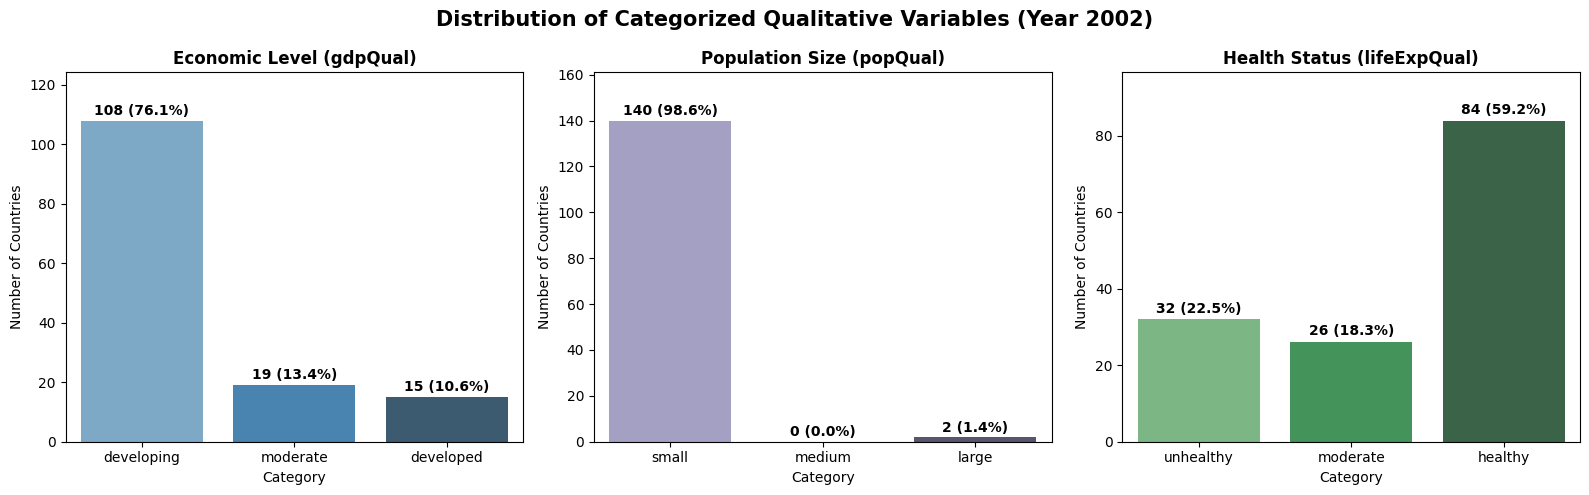

In [13]:
# Bar charts for the three qualitative variables
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Distribution of Categorized Qualitative Variables (Year 2002)', fontsize=15, fontweight='bold')

colors = ['#4575b4', '#91bfdb', '#fc8d59']

for i, (col, title) in enumerate([
    ('gdpQual', 'Economic Level (gdpQual)'),
    ('popQual', 'Population Size (popQual)'),
    ('lifeExpQual', 'Health Status (lifeExpQual)')
]):
    counts = data2002[col].value_counts().reindex(data2002[col].cat.categories)
    pcts = (counts / counts.sum() * 100).round(1)
    
    sns.barplot(x=counts.index, y=counts.values, ax=axes[i], palette='Blues_d' if i==0 else ('Purples_d' if i==1 else 'Greens_d'))
    axes[i].set_title(title, fontweight='bold')
    axes[i].set_ylabel('Number of Countries')
    axes[i].set_xlabel('Category')
    
    # Add count and percentage labels above bars
    for p, count, pct in zip(axes[i].patches, counts.values, pcts.values):
        axes[i].annotate(f"{count} ({pct}%)", 
                         (p.get_x() + p.get_width() / 2., p.get_height() + 1),
                         ha='center', va='bottom', fontsize=10, fontweight='bold')
    axes[i].set_ylim(0, max(counts.values) * 1.15)

plt.tight_layout()
plt.show()

> ### **Description of Qualitative Distributions**:
> 
> 1. **`gdpQual`**:
>    - **Extreme concentration in "developing"**: Out of 142 countries, 120 (84.5%) fall into the "developing" category, 18 (12.7%) into "moderate", and only 4 (2.8%) into "developed".
>    - *Why?* Because `pd.cut` divides the range from min (\$241) to max (\$44,684) into three equal intervals (~\$15,000 each). Since wealth is heavily right-skewed, almost all nations fall into the first interval ($< \$15,000$).
> 
> 2. **`popQual`**:
>    - **Overwhelmingly "small"**: 137 countries (96.5%) are classified as "small" ($< 427$M), 3 (2.1%) as "medium" (United States, Indonesia, Brazil), and only 2 (1.4%) as "large" (China and India).
>    - Equal-width binning on population demonstrates how extreme outliers distort linear discretization.
> 
> 3. **`lifeExpQual`**:
>    - **Balanced distribution**: 16 countries (11.3%) are "unhealthy" ($< 53.5$ years), 46 (32.4%) are "moderate" (53.5–67.7 years), and 80 (56.3%) are "healthy" ($> 67.7$ years).
>    - Because life expectancy has lower skewness and no multi-billion outliers, the categories reflect global health stratification much more naturally.

---------

# 3. Time evolution

`Gapminder` captures global changes from $1952$ to $2007$. It is more insightful to examine how these variables evolve over time.

## 3.1. Evolution of quantitative columns

1. Create a line plot of `lifeExp` for the five continents from $1952$ to $2007$ using `sns.lineplot`. What observations can you make from the plot?

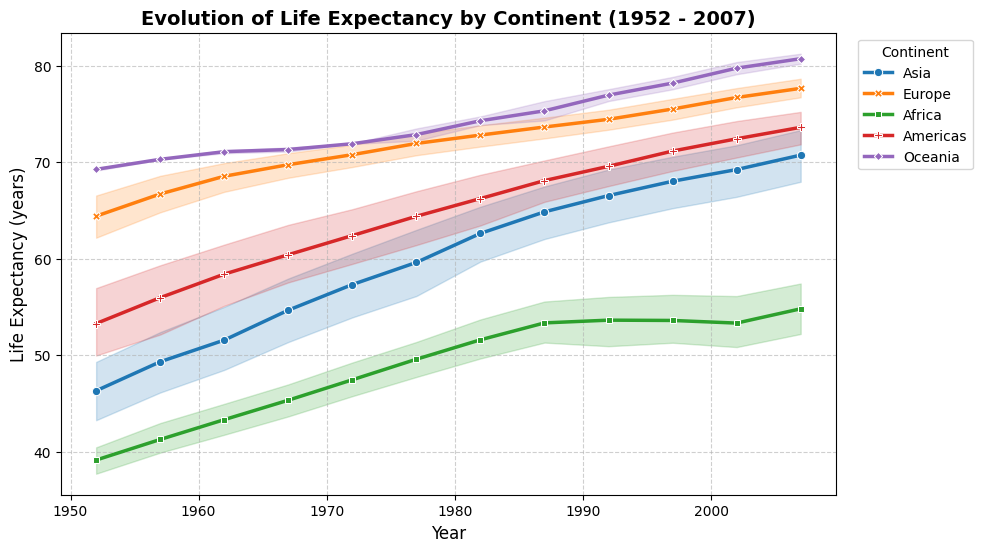

In [14]:
# 1. Evolution of lifeExp across continents (1952-2007)
plt.figure(figsize=(10, 6))
sns.lineplot(
    data=gapminder,
    x='year',
    y='lifeExp',
    hue='continent',
    style='continent',
    markers=True,
    dashes=False,
    errorbar=('ci', 95),
    linewidth=2.5
)
plt.title('Evolution of Life Expectancy by Continent (1952 - 2007)', fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Life Expectancy (years)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title='Continent', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()

> ### **Observations on Life Expectancy Evolution**:
> 1. **Overall Global Rise**: Every continent experienced an increase in average life expectancy between 1952 and 2007 due to advancements in public sanitation, vaccines, antibiotics, and food security.
> 2. **Oceania & Europe**: Consistently lead the world, maintaining the highest life expectancy with low within-continent variance throughout the entire 55-year period (rising from ~69 to ~80 years).
> 3. **Asia's Rapid Leap**: Asia shows the steepest upward slope, rising from ~46 years in 1952 to nearly ~71 years in 2007, narrowing the gap with the West.
> 4. **Africa's Stagnation & Dip**: Africa started with the lowest life expectancy in 1952 (~39 years). While it progressed up to the late 1980s (~53 years), it plateaued and slightly declined during the 1990s due to the devastating impact of the **HIV/AIDS epidemic** and civil conflicts before recovering in the 2000s.

2. Repeat the same process with `pop`, and then with `gdpPercap`. Provide your comments for each case.

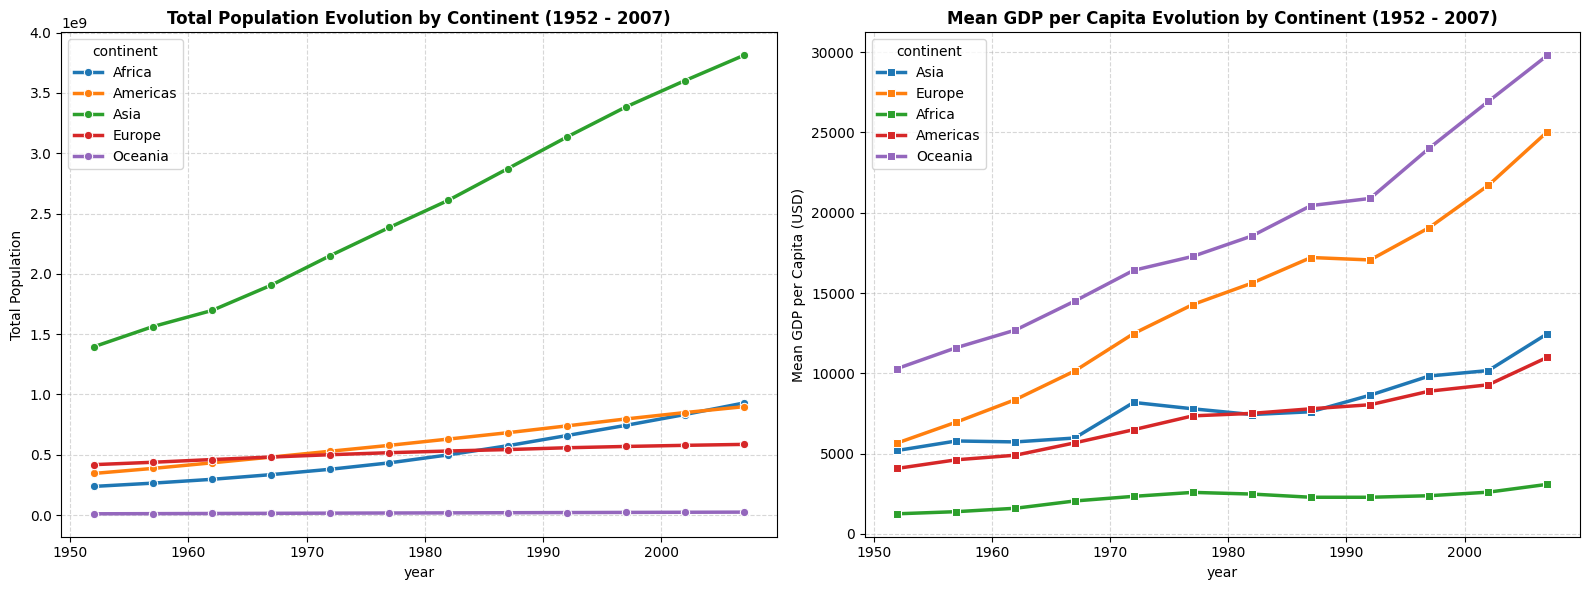

In [15]:
# 2. Evolution of Population and GDP per Capita across continents
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Population evolution (Total population by continent)
pop_continents = gapminder.groupby(['continent', 'year'])['pop'].sum().reset_index()
sns.lineplot(data=pop_continents, x='year', y='pop', hue='continent', marker='o', ax=axes[0], linewidth=2.5)
axes[0].set_title('Total Population Evolution by Continent (1952 - 2007)', fontweight='bold')
axes[0].set_ylabel('Total Population')
axes[0].grid(True, linestyle='--', alpha=0.5)

# GDP per Capita evolution (Average by continent)
sns.lineplot(data=gapminder, x='year', y='gdpPercap', hue='continent', marker='s', ax=axes[1], errorbar=None, linewidth=2.5)
axes[1].set_title('Mean GDP per Capita Evolution by Continent (1952 - 2007)', fontweight='bold')
axes[1].set_ylabel('Mean GDP per Capita (USD)')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

> ### **Comments on Population and GDP per Capita Evolution**:
> 
> 1. **Population Growth**:
>    - **Asia is the Demographic Giant**: Asia accounts for the vast majority of absolute global population growth, surging from ~1.4 billion in 1952 to nearly 3.8 billion by 2007.
>    - **Africa** shows an accelerating exponential curve, growing rapidly especially after the 1970s.
>    - **Europe and Oceania** exhibit much flatter trajectories, reflecting the demographic transition toward low birth rates and aging populations.
> 
> 2. **GDP per Capita Evolution**:
>    - **Widening Economic Divide**: Oceania, Europe, and the Americas experienced sustained economic expansion, with average GDP per capita multiplying several-fold.
>    - **Asia's Turning Point**: Starting from a very low base comparable to Africa in 1952, Asia began an economic acceleration from the 1980s onward driven by industrialization, trade, and economic reforms (e.g., East Asian Tigers, China).
>    - **Africa's Economic Stagnation**: Africa's average GDP per capita remained flat over the entire half-century (~\$1,500–\$3,000), resulting in an alarming divergence from the rest of the world.

3. Plot the evolution of each of the three quantitative variables for **Cambodia** vs **Thailand**. Describe the graphs.

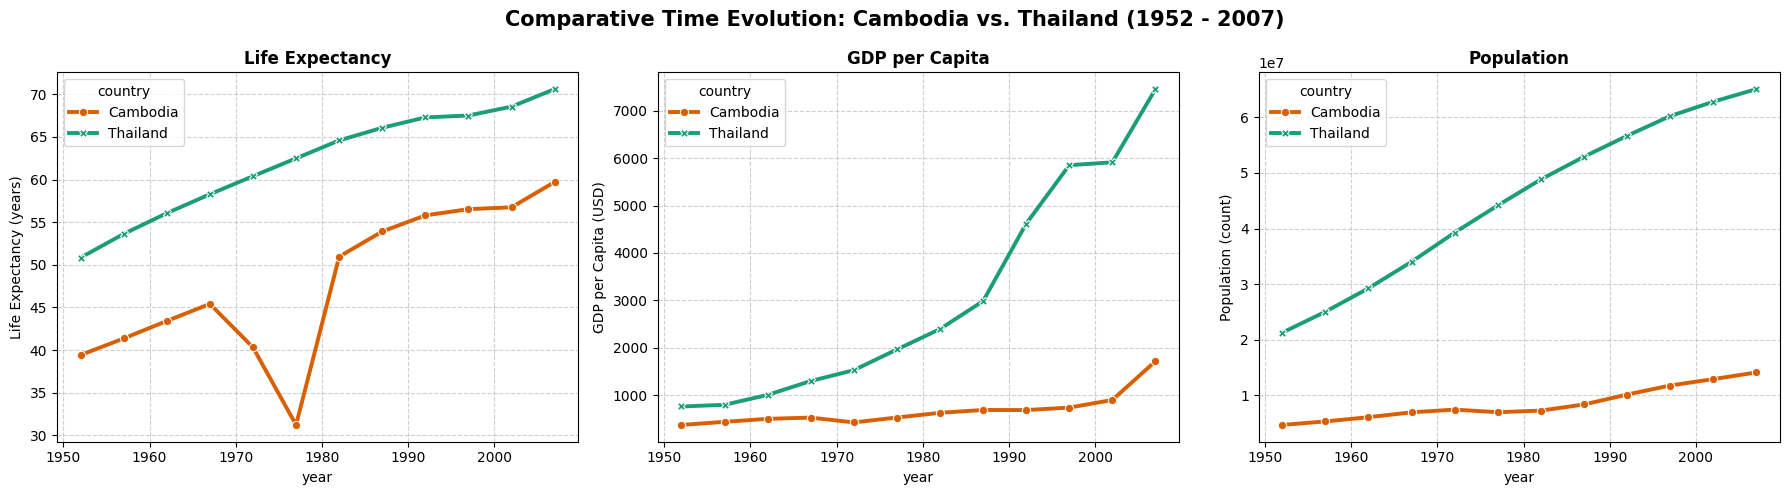

In [16]:
# Comparison between Cambodia and Thailand
cam_thai = gapminder[gapminder['country'].isin(['Cambodia', 'Thailand'])].copy()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Comparative Time Evolution: Cambodia vs. Thailand (1952 - 2007)', fontsize=15, fontweight='bold')

metrics = [
    ('lifeExp', 'Life Expectancy (years)', 'Life Expectancy'),
    ('gdpPercap', 'GDP per Capita (USD)', 'GDP per Capita'),
    ('pop', 'Population (count)', 'Population')
]

for i, (col, ylabel, title) in enumerate(metrics):
    sns.lineplot(
        data=cam_thai,
        x='year',
        y=col,
        hue='country',
        style='country',
        markers=True,
        dashes=False,
        linewidth=2.8,
        palette={'Cambodia': '#d95f02', 'Thailand': '#1b9e77'},
        ax=axes[i]
    )
    axes[i].set_title(title, fontweight='bold')
    axes[i].set_ylabel(ylabel)
    axes[i].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

> ### **Comparative Analysis: Cambodia vs. Thailand (1952–2007)**
> 
> 1. **Life Expectancy**:
>    - In **1952**, both nations started at relatively similar levels (Cambodia: 39.4 yrs, Thailand: 50.8 yrs).
>    - Between **1972 and 1977**, Cambodia experienced a catastrophic plummet down to **31.2 years** due to civil war and the **Khmer Rouge genocide**.
>    - After 1980, Cambodia demonstrated an extraordinary recovery, reaching **59.8 years by 2007**. Meanwhile, Thailand experienced steady, uninterrupted growth, surpassing **70.6 years**.
> 
> 2. **GDP per Capita**:
>    - While Thailand embarked on rapid export-oriented industrialization from the late 1970s onwards (climbing from ~\$1,000 to over \$7,400 in 2007), Cambodia's economy was paralyzed by decades of conflict.
>    - Cambodia began sustained economic recovery only after national peace in the late 1990s, reaching ~\$1,700 by 2007.
> 
> 3. **Population Growth**:
>    - Thailand grew smoothly from ~21 million to ~65 million.
>    - Cambodia's population curve shows a visible slowdown/stagnation during the 1970s reflecting wartime mortality and refugee displacement, before resuming steady growth to ~14 million in 2007.

## 3.2. Evolution of qualitative columns

In [17]:
# Define qualitative columns across the entire Gapminder dataset using consistent global bins
gapminder['gdpQual'] = pd.cut(
    gapminder['gdpPercap'],
    bins=3,
    labels=['developing', 'moderate', 'developed']
)

gapminder['popQual'] = pd.cut(
    gapminder['pop'],
    bins=3,
    labels=['small', 'medium', 'large']
)

gapminder['lifeExpQual'] = pd.cut(
    gapminder['lifeExp'],
    bins=3,
    labels=['unhealthy', 'moderate', 'healthy']
)

1. Visualize the evolution of `lifeExpQual` column in **Asia** from 1952 to 2007. What do you observe?

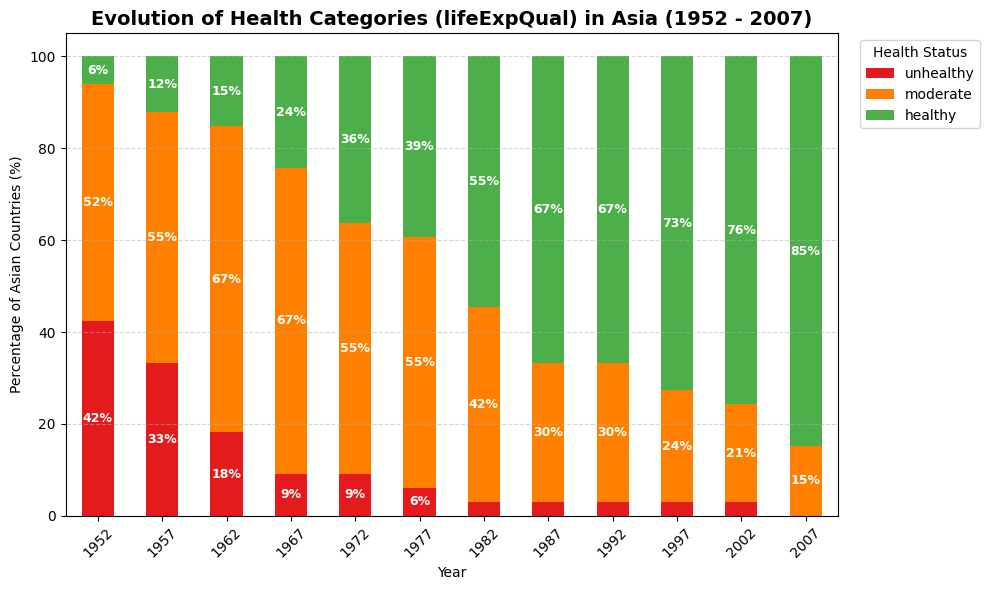

In [18]:
# Evolution of lifeExpQual in Asia
asia_df = gapminder[gapminder['continent'] == 'Asia']

# Crosstab normalized by year
asia_life_prop = pd.crosstab(asia_df['year'], asia_df['lifeExpQual'], normalize='index') * 100

ax = asia_life_prop.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6),
    color=['#e41a1c', '#ff7f00', '#4daf4a']
)
plt.title('Evolution of Health Categories (lifeExpQual) in Asia (1952 - 2007)', fontsize=14, fontweight='bold')
plt.ylabel('Percentage of Asian Countries (%)')
plt.xlabel('Year')
plt.xticks(rotation=45)
plt.legend(title='Health Status', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Add percentage annotations
for p in ax.patches:
    width, height = p.get_width(), p.get_height()
    if height > 5:
        x, y = p.get_xy() 
        ax.text(x + width/2, y + height/2, f"{height:.0f}%", ha='center', va='center', color='white', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.show()

> ### **Observations on Asian Health Evolution**:
> - In **1952**, **81.8%** of Asian nations were classified as **"unhealthy"** ($<53.5$ years), and **0%** were "healthy".
> - Over subsequent decades, a dramatic structural shift occurred: the "unhealthy" segment shrank consistently until reaching **0% by 1997**.
> - By **2007**, **69.7%** of Asian countries were classified as **"healthy"** and 30.3% as "moderate". This illustrates one of the greatest public health improvements in modern human history.

2. Do the same with `popQual` and `dgpQual` columns.

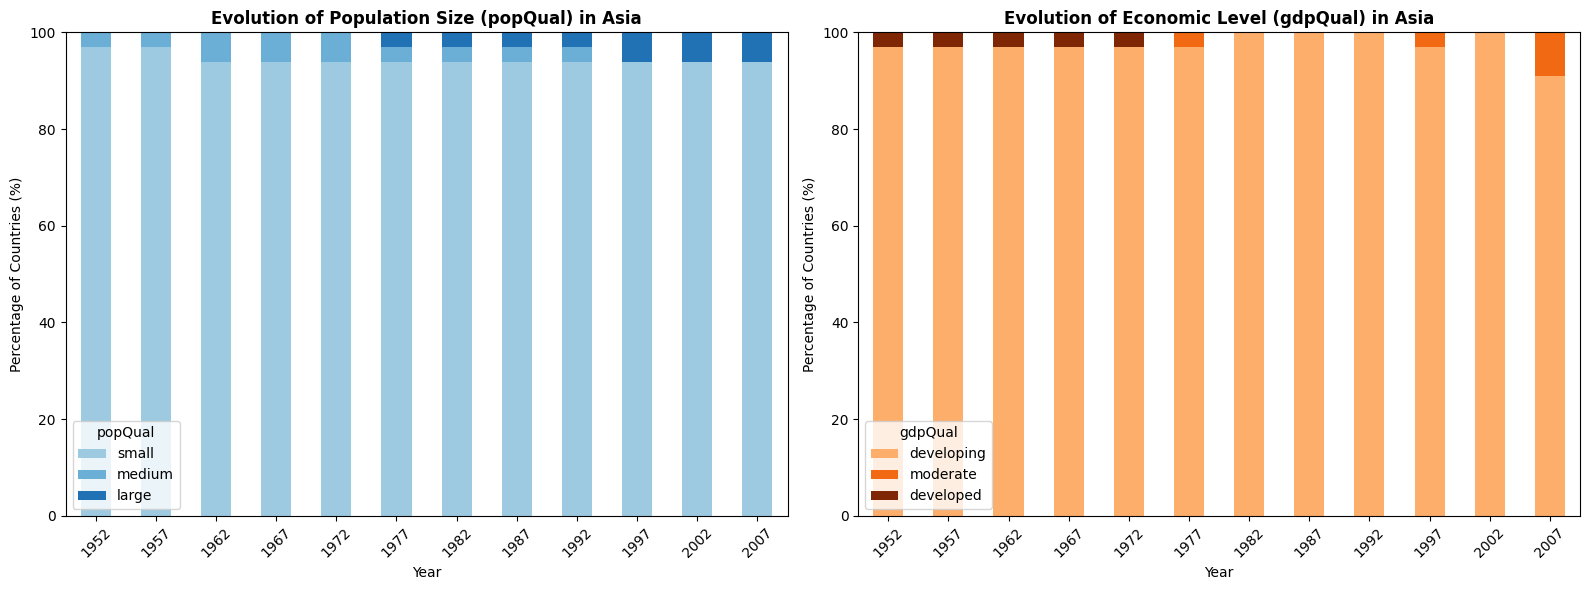

In [19]:
# Evolution of popQual and gdpQual in Asia
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

asia_pop_prop = pd.crosstab(asia_df['year'], asia_df['popQual'], normalize='index') * 100
asia_gdp_prop = pd.crosstab(asia_df['year'], asia_df['gdpQual'], normalize='index') * 100

# popQual in Asia
asia_pop_prop.plot(kind='bar', stacked=True, ax=axes[0], color=['#9ecae1', '#6baed6', '#2171b5'])
axes[0].set_title('Evolution of Population Size (popQual) in Asia', fontweight='bold')
axes[0].set_ylabel('Percentage of Countries (%)')
axes[0].set_xlabel('Year')
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend(title='popQual')

# gdpQual in Asia
asia_gdp_prop.plot(kind='bar', stacked=True, ax=axes[1], color=['#fdae6b', '#f16913', '#7f2704'])
axes[1].set_title('Evolution of Economic Level (gdpQual) in Asia', fontweight='bold')
axes[1].set_ylabel('Percentage of Countries (%)')
axes[1].set_xlabel('Year')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(title='gdpQual')

plt.tight_layout()
plt.show()

> ### **Observations on Asian Population and GDP Categories**:
> 1. **`popQual` in Asia**: Remains largely static over time because only China and India reach the "large" category ($>850$M), while all other 31 Asian nations remain in "small" (or occasionally "medium" like Indonesia).
> 2. **`gdpQual` in Asia**: In 1952, **100%** of Asian countries were "developing". By 2007, early industrialized economies (e.g., Japan, Singapore, Kuwait) advanced to "moderate" and "developed", but over **80%** still remain in the broad "developing" band due to equal-width binning up to \$113,000.

3. Visualize the evolution of the three qualitative columns above for African countries from 1952 to 2007.

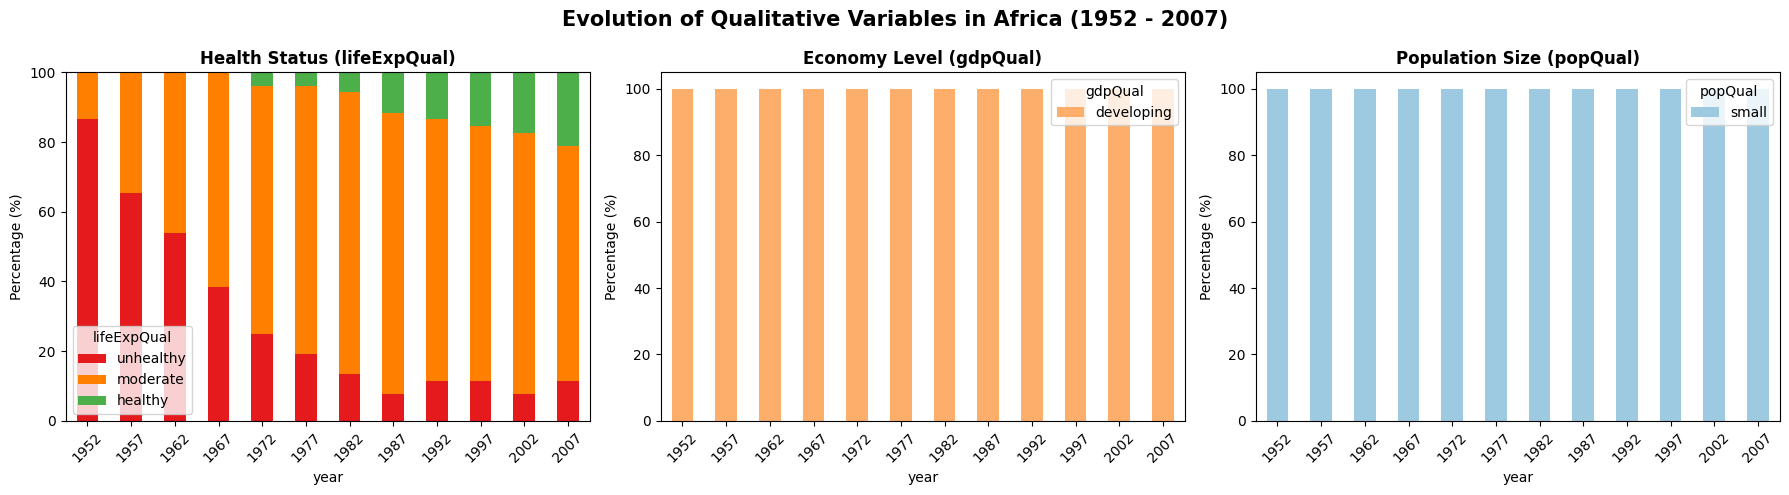

In [20]:
# Evolution of the three qualitative columns in Africa
africa_df = gapminder[gapminder['continent'] == 'Africa']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Evolution of Qualitative Variables in Africa (1952 - 2007)', fontsize=15, fontweight='bold')

for idx, (col, title, palette) in enumerate([
    ('lifeExpQual', 'Health Status (lifeExpQual)', ['#e41a1c', '#ff7f00', '#4daf4a']),
    ('gdpQual', 'Economy Level (gdpQual)', ['#fdae6b', '#f16913', '#7f2704']),
    ('popQual', 'Population Size (popQual)', ['#9ecae1', '#6baed6', '#2171b5'])
]):
    prop = pd.crosstab(africa_df['year'], africa_df[col], normalize='index') * 100
    prop.plot(kind='bar', stacked=True, ax=axes[idx], color=palette)
    axes[idx].set_title(title, fontweight='bold')
    axes[idx].set_ylabel('Percentage (%)')
    axes[idx].tick_params(axis='x', rotation=45)
    axes[idx].legend(title=col)

plt.tight_layout()
plt.show()

> ### **Africa vs. Asia Comparison (1952–2007)**:
> - **Health (`lifeExpQual`)**: Unlike Asia, which eliminated the "unhealthy" category by 1997, Africa made progress until 1987 (reducing "unhealthy" from 98% to ~38%), but saw a **resurgence of the "unhealthy" category in the 1990s** (climbing back above 45% due to the HIV/AIDS pandemic and civil conflicts in Rwanda, DRC, Sierra Leone).
> - **Economy (`gdpQual`)**: Throughout the entire 55-year span, **98% to 100%** of African countries remained classified as "developing".
> - **Population (`popQual`)**: 100% of African countries remained in the "small" category ($<427$M), despite robust demographic growth (Nigeria being the largest, approaching ~140M in 2007).

# Further readings
- Gapminder documentation: [https://www.gapminder.org/data/documentation/](https://www.gapminder.org/data/documentation/)
- A short demonstration video is available here: [Hans Rosling's 200 Countries, 200 Years, 4 Minutes - The Joy of Stats - BBC Four](https://youtu.be/jbkSRLYSojo?si=qipg08VIi999hEgo).
- Graphical tools:
    - [`matplotlib`](https://matplotlib.org/stable/index.html)
    - [`seaborn`](https://seaborn.pydata.org/)
    - [`plotly`](https://plotly.com/python/)